# TRUSTSR Lab 02.06 — Transactional Persistence and Restart Recovery

**Project:** TRUSTSR — Trust-Aware Causal Semantic Recovery for Long-Horizon Agentic Systems  
**Phase:** Lab 02 — Recovery implementation  
**Status:** Synthetic local simulation / research prototype  
**Version:** 0.1.0

## Connection to Lab 02.05
Lab 02.05 showed a race in an intentionally unsafe in-memory implementation and used a Python lock to serialize updates within one process. This lab moves the high-water mark into SQLite and uses a transaction plus a conditional update to test persistent monotonic version advancement across a simulated connection restart.

## Policy
A checkpoint can advance the high-water mark only if its signature verifies, its version is a positive integer (booleans are rejected), and a SQLite transaction confirms that its version exceeds the current mark. The conditional update and commit occur within one transaction. A simulated failure before commit must roll back. Rejected or stale checkpoints must not advance the mark.

## Scenarios
- Accept a newer signed checkpoint.
- Reject an older/equal replay.
- Reject an invalid signature.
- Simulate failure after the update statement but before commit, then verify rollback.
- Close and reopen the database connection and verify the mark persists.
- Submit concurrent same-version candidates through separate SQLite connections.

## Evidence boundary
This is a **synthetic local test** using SQLite in the notebook runtime. It is not a distributed database test, production durability certification, or formal proof. The signing key and database are test fixtures; do not use this notebook as production key management.

## 1. Install dependencies and import

In [1]:
%pip -q install cryptography pandas matplotlib

In [2]:
import os, json, copy, sqlite3, tempfile, threading, sys, platform
from datetime import datetime, timezone
import pandas as pd
import matplotlib.pyplot as plt
from cryptography.hazmat.primitives.asymmetric.ed25519 import Ed25519PrivateKey
from cryptography.exceptions import InvalidSignature

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("SQLite:", sqlite3.sqlite_version)
print("cryptography:", __import__("cryptography").__version__)
print("Execution UTC:", datetime.now(timezone.utc).isoformat())
print("Evidence type: synthetic local simulation only")

Python: 3.12.3
Platform: Linux-6.18.44-fc-v114-x86_64-with-glibc2.39
SQLite: 3.45.1
cryptography: 46.0.6
Execution UTC: 2026-10-11T10:26:33.189635+00:00
Evidence type: synthetic local simulation only


## 2. Create signed checkpoint fixtures

In [3]:
private_key = Ed25519PrivateKey.generate()
public_key = private_key.public_key()

def canonical_bytes(obj):
    return json.dumps(obj, sort_keys=True, separators=(",", ":"), ensure_ascii=False).encode("utf-8")

def make_checkpoint(version, value):
    return {"schema_version": 1, "checkpoint_version": version, "state": {"M1": value}}

def sign_checkpoint(checkpoint):
    return {"checkpoint": copy.deepcopy(checkpoint), "signature": private_key.sign(canonical_bytes(checkpoint))}

def verify_signed(signed):
    try:
        public_key.verify(signed["signature"], canonical_bytes(signed["checkpoint"]))
        return True
    except (InvalidSignature, KeyError, TypeError):
        return False

signed = {v: sign_checkpoint(make_checkpoint(v, f"synthetic state version {v}")) for v in range(1, 7)}
assert all(verify_signed(item) for item in signed.values())
print("Prepared signed versions:", sorted(signed))
print("Signature fixture assertions passed.")

Prepared signed versions: [1, 2, 3, 4, 5, 6]
Signature fixture assertions passed.


## 3. Initialize a SQLite high-water store

In [4]:
db_fd, db_path = tempfile.mkstemp(prefix="trustsr_lab0206_", suffix=".sqlite")
os.close(db_fd)

def connect_db():
    connection = sqlite3.connect(db_path, timeout=10, isolation_level=None, check_same_thread=False)
    connection.execute("PRAGMA journal_mode=WAL")
    connection.execute("PRAGMA synchronous=FULL")
    connection.execute("""
        CREATE TABLE IF NOT EXISTS checkpoint_guard (
            singleton_id INTEGER PRIMARY KEY CHECK (singleton_id = 1),
            high_water_mark INTEGER NOT NULL CHECK (high_water_mark >= 0)
        )
    """)
    connection.execute("INSERT OR IGNORE INTO checkpoint_guard(singleton_id, high_water_mark) VALUES (1, 0)")
    return connection

conn = connect_db()
print("SQLite test database initialized.")
print("Initial high-water mark:", conn.execute("SELECT high_water_mark FROM checkpoint_guard WHERE singleton_id=1").fetchone()[0])

SQLite test database initialized.
Initial high-water mark: 0


## 4. Implement transactional compare-and-update

In [5]:
def read_mark(connection):
    row = connection.execute("SELECT high_water_mark FROM checkpoint_guard WHERE singleton_id=1").fetchone()
    return int(row[0])

def consider_transactionally(signed_checkpoint, simulate_failure_before_commit=False, connection=None):
    db = connection or conn
    if not verify_signed(signed_checkpoint):
        return {"accepted": False, "reason": "invalid_signature", "high_water_mark": read_mark(db)}
    version = signed_checkpoint["checkpoint"].get("checkpoint_version")
    if not isinstance(version, int) or isinstance(version, bool) or version < 1:
        return {"accepted": False, "reason": "invalid_version", "high_water_mark": read_mark(db)}
    try:
        db.execute("BEGIN IMMEDIATE")
        before = read_mark(db)
        if version <= before:
            db.execute("ROLLBACK")
            return {"accepted": False, "reason": "replay_or_stale_version", "high_water_mark": before}
        cursor = db.execute(
            "UPDATE checkpoint_guard SET high_water_mark=? WHERE singleton_id=1 AND high_water_mark=?",
            (version, before)
        )
        if cursor.rowcount != 1:
            db.execute("ROLLBACK")
            return {"accepted": False, "reason": "compare_and_update_conflict", "high_water_mark": read_mark(db)}
        if simulate_failure_before_commit:
            db.execute("ROLLBACK")
            return {"accepted": False, "reason": "simulated_failure_rolled_back", "high_water_mark": read_mark(db)}
        db.execute("COMMIT")
        return {"accepted": True, "reason": "committed", "high_water_mark": read_mark(db)}
    except Exception as exc:
        try:
            db.execute("ROLLBACK")
        except sqlite3.Error:
            pass
        return {"accepted": False, "reason": f"database_error:{type(exc).__name__}", "high_water_mark": read_mark(db)}

print("Transactional compare-and-update function defined.")

Transactional compare-and-update function defined.


## 5. Run version, signature, and rollback scenarios

In [6]:
scenario_rows = []

def record_scenario(name, result, expected_mark):
    actual_mark = read_mark(conn)
    scenario_rows.append({
        "scenario": name, "accepted": result["accepted"], "reason": result["reason"],
        "reported_mark": result["high_water_mark"], "actual_mark": actual_mark,
        "expected_mark": expected_mark, "mark_matches_expected": actual_mark == expected_mark,
    })

r = consider_transactionally(signed[2])
record_scenario("accept_v2", r, 2)
assert r["accepted"] and read_mark(conn) == 2

r = consider_transactionally(signed[1])
record_scenario("reject_stale_v1", r, 2)
assert not r["accepted"] and read_mark(conn) == 2

r = consider_transactionally(signed[2])
record_scenario("reject_equal_v2_replay", r, 2)
assert not r["accepted"] and read_mark(conn) == 2

r = consider_transactionally(signed[4], simulate_failure_before_commit=True)
record_scenario("rollback_before_commit_v4", r, 2)
assert not r["accepted"] and r["reason"] == "simulated_failure_rolled_back"
assert read_mark(conn) == 2

tampered = copy.deepcopy(signed[5])
tampered["checkpoint"]["state"]["M1"] = "tampered state"
r = consider_transactionally(tampered)
record_scenario("reject_invalid_signature", r, 2)
assert not r["accepted"] and read_mark(conn) == 2

r = consider_transactionally(signed[3])
record_scenario("accept_v3_after_rollback", r, 3)
assert r["accepted"] and read_mark(conn) == 3

scenario_df = pd.DataFrame(scenario_rows)
display(scenario_df)

                    scenario  accepted                         reason  reported_mark  actual_mark  expected_mark  mark_matches_expected
0                  accept_v2      True                      committed              2            2              2                   True
1            reject_stale_v1     False        replay_or_stale_version              2            2              2                   True
2     reject_equal_v2_replay     False        replay_or_stale_version              2            2              2                   True
3  rollback_before_commit_v4     False  simulated_failure_rolled_back              2            2              2                   True
4   reject_invalid_signature     False              invalid_signature              2            2              2                   True
5   accept_v3_after_rollback      True                      committed              3            3              3                   True

## 6. Verify persistence across connection restart

In [7]:
mark_before_close = read_mark(conn)
conn.close()
# Reopen the same database file. This models connection restart, not machine power loss.
conn = connect_db()
mark_after_reopen = read_mark(conn)

restart_df = pd.DataFrame([{
    "mark_before_close": mark_before_close, "mark_after_reopen": mark_after_reopen,
    "persisted_across_connection_restart": mark_before_close == mark_after_reopen,
    "evidence_type": "synthetic local SQLite test",
}])
display(restart_df)
assert mark_before_close == 3
assert mark_after_reopen == mark_before_close
print("PASS: high-water mark persisted across database connection close/reopen.")

   mark_before_close  mark_after_reopen  persisted_across_connection_restart                evidence_type
0                  3                  3                                 True  synthetic local SQLite test

PASS: high-water mark persisted across database connection close/reopen.


## 7. Concurrent same-version submissions on separate connections

In [8]:
race_barrier = threading.Barrier(2)
race_results = []
race_results_lock = threading.Lock()

def race_worker(worker_id):
    local_conn = connect_db()
    try:
        race_barrier.wait()
        result = consider_transactionally(signed[5], connection=local_conn)
        result["worker_id"] = worker_id
        with race_results_lock:
            race_results.append(result)
    finally:
        local_conn.close()

threads = [threading.Thread(target=race_worker, args=(i,)) for i in (1, 2)]
for thread in threads: thread.start()
for thread in threads: thread.join()

race_df = pd.DataFrame(race_results)
display(race_df)
final_mark_after_race = read_mark(conn)
print("Final mark after concurrent version-5 submissions:", final_mark_after_race)
assert sum(bool(item["accepted"]) for item in race_results) == 1
assert final_mark_after_race == 5
print("PASS: exactly one concurrent same-version submission committed.")

   accepted                   reason  high_water_mark  worker_id
0      True                committed                5          2
1     False  replay_or_stale_version                5          1

Final mark after concurrent version-5 submissions: 5
PASS: exactly one concurrent same-version submission committed.


## 8. Plot outcomes

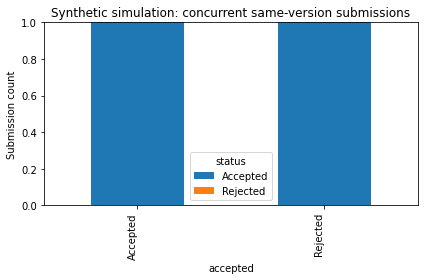

In [9]:
plot_df = scenario_df.copy()
plot_df["status"] = plot_df["accepted"].map({True: "Accepted", False: "Rejected"})
ax = plot_df.groupby(["scenario", "status"]).size().unstack(fill_value=0).plot(kind="bar", stacked=True, figsize=(11, 5))
ax.set_ylabel("Scenario count")
ax.set_title("Synthetic simulation: transactional checkpoint policy")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

race_counts = race_df["accepted"].value_counts().rename(index={True: "Accepted", False: "Rejected"})
race_counts.plot(kind="bar", figsize=(6, 4), title="Synthetic simulation: concurrent same-version submissions")
plt.ylabel("Submission count")
plt.tight_layout()
plt.show()

## 9. Export CSV artifacts

In [10]:
scenario_df.to_csv("trustsr_lab02_06_transaction_scenarios.csv", index=False)
restart_df.to_csv("trustsr_lab02_06_restart_persistence.csv", index=False)
race_df.to_csv("trustsr_lab02_06_concurrent_submissions.csv", index=False)
print("Generated files:")
print("- trustsr_lab02_06_transaction_scenarios.csv")
print("- trustsr_lab02_06_restart_persistence.csv")
print("- trustsr_lab02_06_concurrent_submissions.csv")

Generated files:
- trustsr_lab02_06_transaction_scenarios.csv
- trustsr_lab02_06_restart_persistence.csv
- trustsr_lab02_06_concurrent_submissions.csv


## 10. Final assertions

In [11]:
assert scenario_df["mark_matches_expected"].all()
assert restart_df["persisted_across_connection_restart"].iloc[0]
assert sum(bool(item["accepted"]) for item in race_results) == 1
assert final_mark_after_race == 5
assert read_mark(conn) == 5
print("PASS: stale/equal checkpoints rejected.")
print("PASS: invalid signature rejected.")
print("PASS: simulated pre-commit failure rolled back.")
print("PASS: SQLite mark persisted across connection reopen.")
print("PASS: concurrent same-version race produced exactly one committed update.")
print("All Lab 02.06 assertions passed.")

PASS: stale/equal checkpoints rejected.
PASS: invalid signature rejected.
PASS: simulated pre-commit failure rolled back.
PASS: SQLite mark persisted across connection reopen.
PASS: concurrent same-version race produced exactly one committed update.
All Lab 02.06 assertions passed.


## 11. Interpretation and limitations

### What this synthetic local test demonstrates
The notebook tests a SQLite transaction that checks and updates the high-water mark, rolls back a simulated pre-commit failure, reopens the same database file, and submits duplicate versions through separate connections. Assertions check that only one of two same-version submissions commits and rejected updates do not advance the mark.

### Critical limitations
- Reopening a connection is not the same as testing machine crash, power loss, filesystem corruption, or runtime eviction.
- SQLite transactions in one local database are not a distributed consensus protocol.
- The test uses a generated key pair and synthetic checkpoint contents.
- `PRAGMA synchronous=FULL` is a configuration choice, not independent proof of durability on every filesystem or host.
- The high-water mark alone does not establish that checkpoint state is semantically safe, complete, or free from poisoning.
- This is not a production-ready checkpoint manager, real-agent evaluation, or formal security proof.

### Next step
Lab 02.07 should add a structured audit trail with transaction IDs, outcomes, version before/after, failure reason, and tamper-evident log chaining; test whether the audit trail detects modified or missing events. Label all results as synthetic until evaluated on a documented implementation.